In [1]:
import sys

print(sys.executable)
print(sys.version)

d:\Customer Churn Analysis & Prediction\churn_env\Scripts\python.exe
3.14.0 (tags/v3.14.0:ebf955d, Oct  7 2025, 10:15:03) [MSC v.1944 64 bit (AMD64)]


In [2]:
import pandas as pd

print(pd.__version__)

3.0.6


In [3]:
df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.shape


(7043, 21)

In [6]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [8]:
df["TotalCharges"].head(20)

0       29.85
1      1889.5
2      108.15
3     1840.75
4      151.65
5       820.5
6      1949.4
7       301.9
8     3046.05
9     3487.95
10     587.45
11      326.8
12     5681.1
13     5036.3
14    2686.05
15    7895.15
16    1022.95
17    7382.25
18     528.35
19     1862.9
Name: TotalCharges, dtype: str

In [9]:
(df["TotalCharges"].str.strip() == "").sum()

np.int64(11)

In [10]:
df[df["TotalCharges"].str.strip() == ""]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [11]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].replace(r"^\s*$", "0", regex=True)
)

In [12]:
df["TotalCharges"].dtype

dtype('float64')

In [13]:
df[df["tenure"] == 0][
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,0.0
753,3115-CZMZD,0,20.25,0.0
936,5709-LVOEQ,0,80.85,0.0
1082,4367-NUYAO,0,25.75,0.0
1340,1371-DWPAZ,0,56.05,0.0
3331,7644-OMVMY,0,19.85,0.0
3826,3213-VVOLG,0,25.35,0.0
4380,2520-SGTTA,0,20.00,0.0
5218,2923-ARZLG,0,19.70,0.0
6670,4075-WKNIU,0,73.35,0.0


In [14]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
df["customerID"].duplicated().sum()

np.int64(0)

In [17]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [18]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [19]:
df["Churn"].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [20]:
import matplotlib.pyplot as plt

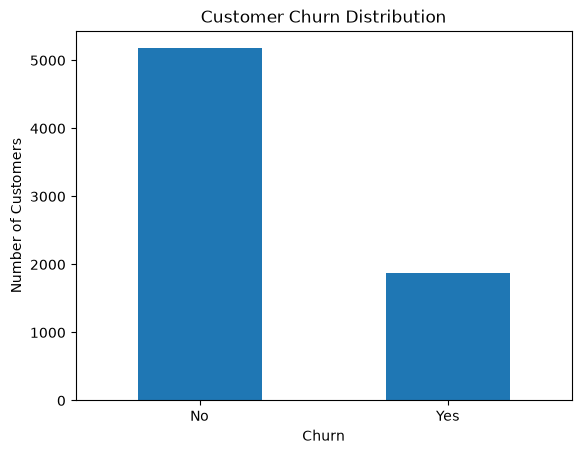

In [21]:
churn_counts = df["Churn"].value_counts()

churn_counts.plot(kind="bar")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

In [22]:
df["Contract"].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

In [23]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"]
)

contract_churn

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


In [24]:
contract_churn_rate = (
    df.groupby("Contract")["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
)

contract_churn_rate

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Churn, dtype: float64

### Finding: Contract Type and Churn

- Month-to-month customers have the highest churn rate at 42.71%.
- One-year contract customers have a much lower churn rate of 11.27%.
- Two-year contract customers have the lowest churn rate at 2.83%.
- In this dataset, longer contract periods are associated with substantially lower customer churn.

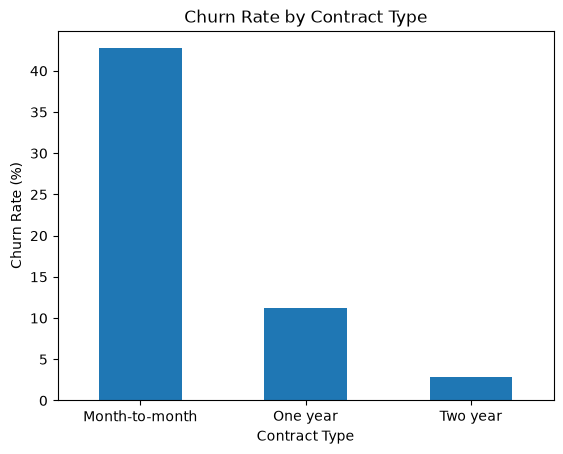

In [25]:
contract_churn_rate.plot(kind="bar")

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

In [26]:
df.groupby("Churn")["tenure"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,37.569965,24.113777,0.0,15.0,38.0,61.0,72.0
Yes,1869.0,17.979133,19.531123,1.0,2.0,10.0,29.0,72.0


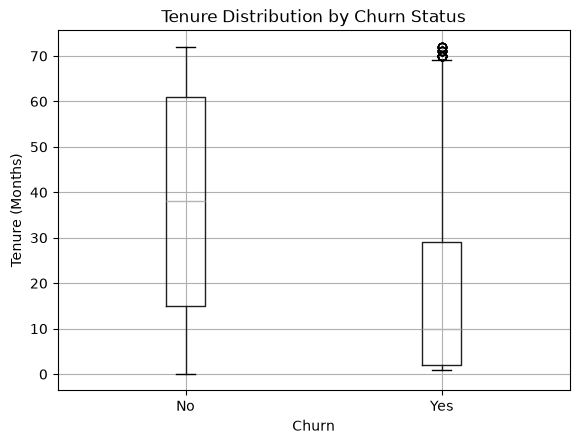

In [27]:
df.boxplot(
    column="tenure",
    by="Churn"
)

plt.title("Tenure Distribution by Churn Status")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.show()

### Finding: Tenure and Churn

- Customers who churned had a median tenure of 10 months.
- Customers who stayed had a median tenure of 38 months.
- Churned customers generally had much shorter tenure than non-churned customers.
- This suggests that churn is more concentrated among relatively newer customers in this dataset.

In [28]:
df.groupby("Churn")["MonthlyCharges"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,61.265124,31.092648,18.25,25.10,64.425,88.4,118.75
Yes,1869.0,74.441332,24.666053,18.85,56.15,79.650,94.2,118.35


### Finding: Monthly Charges and Churn

- Customers who churned had an average monthly charge of 74.44, compared with 61.27 for customers who stayed.
- The median monthly charge was 79.65 for churned customers and 64.43 for non-churned customers.
- Customers who churned generally had higher monthly charges.
- Higher monthly charges are associated with churn in this dataset, but this does not by itself establish a causal relationship.

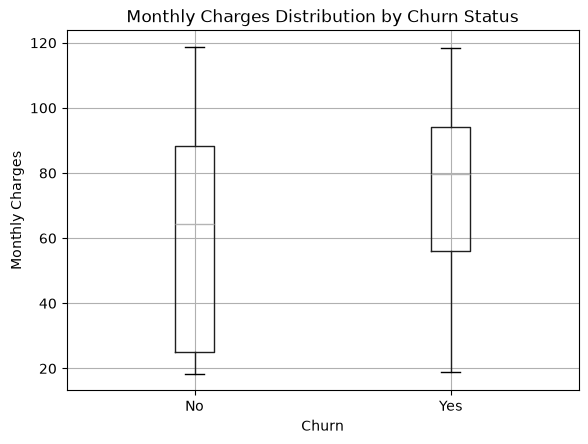

In [29]:
df.boxplot(
    column="MonthlyCharges",
    by="Churn"
)

plt.title("Monthly Charges Distribution by Churn Status")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()

In [30]:
df["InternetService"].value_counts()

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

In [31]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"]
)

internet_churn

Churn,No,Yes
InternetService,,
DSL,1962,459
Fiber optic,1799,1297
No,1413,113


In [32]:
internet_churn_rate = (
    df.groupby("InternetService")["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
)

internet_churn_rate

InternetService
DSL            18.959108
Fiber optic    41.892765
No              7.404980
Name: Churn, dtype: float64

### Finding: Internet Service and Churn

- Fiber optic customers have the highest churn rate at 41.89%.
- DSL customers have a churn rate of 18.96%.
- Customers without internet service have the lowest churn rate at 7.40%.
- Fiber optic service is strongly associated with higher churn in this dataset.
- This is an association and does not by itself prove that fiber optic service causes churn.

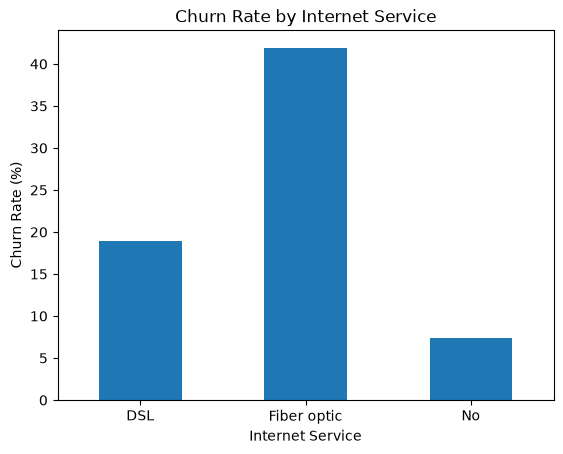

In [33]:
internet_churn_rate.plot(kind="bar")

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

In [34]:
df.groupby("InternetService")["MonthlyCharges"].describe()

,count,mean,std,min,25%,50%,75%,max
InternetService,,,,,,,,
DSL,2421.0,58.102169,16.259522,23.45,46.20,56.150,69.90,94.80
Fiber optic,3096.0,91.500129,12.663039,67.75,80.55,91.675,101.15,118.75
No,1526.0,21.079194,2.164221,18.25,19.70,20.150,20.90,26.90


### Finding: Internet Service and Monthly Charges

- Fiber optic customers have the highest average monthly charge at 91.50.
- DSL customers have an average monthly charge of 58.10.
- Customers without internet service have the lowest average monthly charge at 21.08.
- Fiber optic customers also have the highest churn rate at 41.89%.
- This suggests that internet service type, monthly charges, and churn may be related.
- However, these results do not prove that higher charges cause churn because other customer characteristics may also influence the relationship.

In [35]:
pd.crosstab(
    df["InternetService"],
    df["Contract"]
)

Contract,Month-to-month,One year,Two year
InternetService,,,
DSL,1223,570,628
Fiber optic,2128,539,429
No,524,364,638


In [36]:
internet_contract_pct = pd.crosstab(
    df["InternetService"],
    df["Contract"],
    normalize="index"
) * 100

internet_contract_pct

Contract,Month-to-month,One year,Two year
InternetService,,,
DSL,50.516316,23.543990,25.939694
Fiber optic,68.733850,17.409561,13.856589
No,34.338139,23.853211,41.808650


### Finding: Internet Service and Contract Type

- 68.73% of Fiber optic customers are on month-to-month contracts.
- This is higher than DSL customers (50.52%) and customers without internet service (34.34%).
- Fiber optic customers also have higher monthly charges and a higher observed churn rate.
- These findings suggest that InternetService, Contract, MonthlyCharges, and Churn are interconnected.
- Further analysis and machine-learning modeling are needed to understand their combined predictive relationships.

In [37]:
service_contract_churn = (
    df.groupby(["InternetService", "Contract"])["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
)

service_contract_churn

InternetService  Contract      
DSL              Month-to-month    32.215863
                 One year           9.298246
                 Two year           1.910828
Fiber optic      Month-to-month    54.605263
                 One year          19.294991
                 Two year           7.226107
No               Month-to-month    18.893130
                 One year           2.472527
                 Two year           0.783699
Name: Churn, dtype: float64

### Finding: Internet Service, Contract Type, and Churn

- Fiber optic customers have the highest churn rate within every contract type.
- Among month-to-month customers, Fiber optic customers have a churn rate of 54.61%, compared with 32.22% for DSL and 18.89% for customers without internet service.
- Longer contracts are associated with lower churn across all three internet-service groups.
- Therefore, the high churn among Fiber optic customers cannot be explained only by their greater use of month-to-month contracts.
- Internet service type and contract type both appear to contain useful information related to churn.

In [38]:
service_contract_churn_table = service_contract_churn.unstack()

service_contract_churn_table

Contract,Month-to-month,One year,Two year
InternetService,,,
DSL,32.215863,9.298246,1.910828
Fiber optic,54.605263,19.294991,7.226107
No,18.893130,2.472527,0.783699


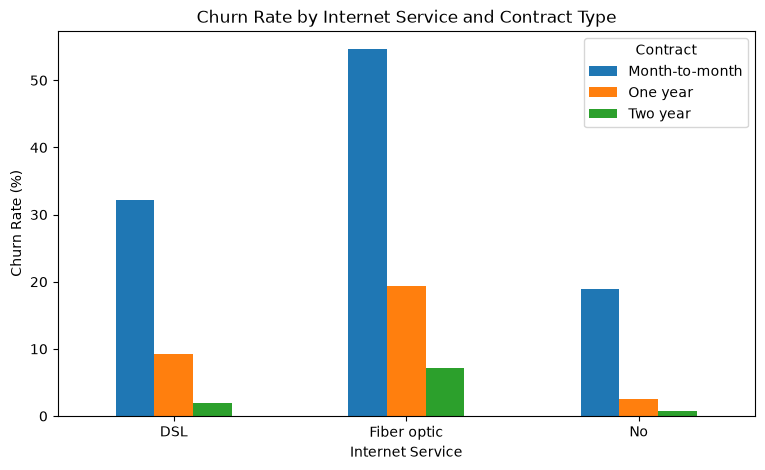

In [39]:
service_contract_churn_table.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Churn Rate by Internet Service and Contract Type")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.legend(title="Contract")
plt.show()

In [40]:
df["TechSupport"].value_counts()

TechSupport
No                     3473
Yes                    2044
No internet service    1526
Name: count, dtype: int64

In [41]:
techsupport_churn = pd.crosstab(
    df["TechSupport"],
    df["Churn"]
)

techsupport_churn

Churn,No,Yes
TechSupport,,
No,2027,1446
No internet service,1413,113
Yes,1734,310


In [42]:
techsupport_churn_rate = (
    df.groupby("TechSupport")["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
)

techsupport_churn_rate

TechSupport
No                     41.635474
No internet service     7.404980
Yes                    15.166341
Name: Churn, dtype: float64

### Finding: Tech Support and Churn

- Customers without Tech Support have the highest churn rate at 41.64%.
- Customers with Tech Support have a much lower churn rate of 15.17%.
- Customers without internet service have a churn rate of 7.40%.
- Among internet-service customers, having Tech Support is associated with substantially lower churn.
- This relationship does not by itself prove that Tech Support causes lower churn.

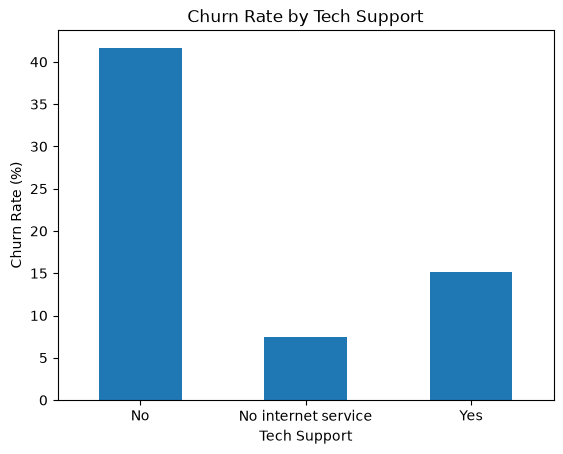

In [43]:
techsupport_churn_rate.plot(kind="bar")

plt.title("Churn Rate by Tech Support")
plt.xlabel("Tech Support")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

In [44]:
df["PaymentMethod"].value_counts()

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

In [45]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"]
)

payment_churn

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),1286,258
Credit card (automatic),1290,232
Electronic check,1294,1071
Mailed check,1304,308


In [46]:
payment_churn_rate = (
    df.groupby("PaymentMethod")["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
)

payment_churn_rate

PaymentMethod
Bank transfer (automatic)    16.709845
Credit card (automatic)      15.243101
Electronic check             45.285412
Mailed check                 19.106700
Name: Churn, dtype: float64

### Finding: Payment Method and Churn

- Electronic check customers have the highest churn rate at 45.29%.
- Mailed check customers have a churn rate of 19.11%.
- Bank transfer (automatic) customers have a churn rate of 16.71%.
- Credit card (automatic) customers have the lowest churn rate at 15.24%.
- Electronic check is strongly associated with higher churn in this dataset.
- This does not prove that the payment method itself causes churn because payment method may also be related to other customer characteristics.

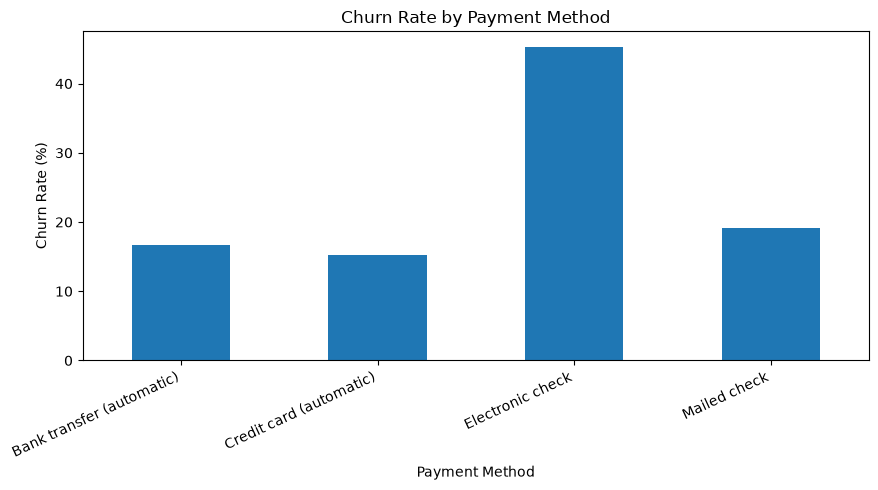

In [47]:
payment_churn_rate.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

In [48]:
payment_contract = pd.crosstab(
    df["PaymentMethod"],
    df["Contract"]
)

payment_contract

Contract,Month-to-month,One year,Two year
PaymentMethod,,,
Bank transfer (automatic),589,391,564
Credit card (automatic),543,398,581
Electronic check,1850,347,168
Mailed check,893,337,382


In [49]:
payment_contract_pct = pd.crosstab(
    df["PaymentMethod"],
    df["Contract"],
    normalize="index"
) * 100

payment_contract_pct

Contract,Month-to-month,One year,Two year
PaymentMethod,,,
Bank transfer (automatic),38.147668,25.323834,36.528497
Credit card (automatic),35.676741,26.149803,38.173456
Electronic check,78.224101,14.672304,7.103594
Mailed check,55.397022,20.905707,23.697270


### Finding: Payment Method and Contract Type

- 78.22% of Electronic check customers are on month-to-month contracts.
- This is considerably higher than Bank transfer (38.15%) and Credit card (35.68%) customers.
- Electronic check customers also have the highest overall churn rate at 45.29%.
- Since month-to-month contracts are also associated with high churn, the relationship between Electronic check and churn may partly overlap with contract type.
- Further analysis is needed to compare payment methods within the same contract type.

In [50]:
payment_contract_churn = (
    df.groupby(["PaymentMethod", "Contract"])["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
)

payment_contract_churn

PaymentMethod              Contract      
Bank transfer (automatic)  Month-to-month    34.125637
                           One year           9.718670
                           Two year           3.368794
Credit card (automatic)    Month-to-month    32.780847
                           One year          10.301508
                           Two year           2.237522
Electronic check           Month-to-month    53.729730
                           One year          18.443804
                           Two year           7.738095
Mailed check               Month-to-month    31.578947
                           One year           6.824926
                           Two year           0.785340
Name: Churn, dtype: float64

### Finding: Payment Method, Contract Type, and Churn

- Electronic check has the highest observed churn rate within every contract type.
- Among month-to-month customers, Electronic check users have a churn rate of 53.73%, compared with approximately 31.58%–34.13% for the other payment methods.
- Electronic check also has the highest churn rate among one-year and two-year contract customers.
- Therefore, the high churn associated with Electronic check cannot be explained only by the large proportion of Electronic check customers on month-to-month contracts.
- Payment method appears to contain additional information related to churn, although this analysis does not establish causation.

In [51]:
payment_contract_churn_table = payment_contract_churn.unstack()

payment_contract_churn_table

Contract,Month-to-month,One year,Two year
PaymentMethod,,,
Bank transfer (automatic),34.125637,9.718670,3.368794
Credit card (automatic),32.780847,10.301508,2.237522
Electronic check,53.729730,18.443804,7.738095
Mailed check,31.578947,6.824926,0.785340


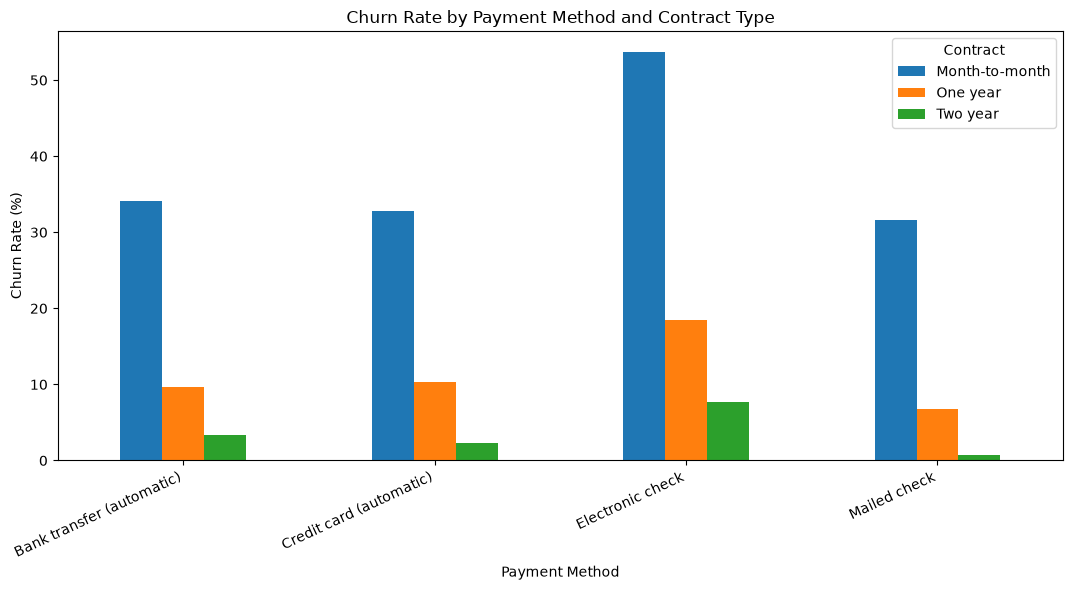

In [52]:
payment_contract_churn_table.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Churn Rate by Payment Method and Contract Type")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=25, ha="right")
plt.legend(title="Contract")
plt.tight_layout()
plt.show()

### Payment Method Analysis — Conclusion

- Electronic check customers have the highest overall churn rate.
- 78.22% of Electronic check customers use month-to-month contracts.
- However, contract type alone does not explain the higher churn associated with Electronic check.
- Within every contract type, Electronic check customers still show the highest observed churn rate.
- The highest-risk combination observed is Electronic check with a month-to-month contract, with a churn rate of approximately 53.73%.
- Therefore, both Payment Method and Contract Type appear to provide useful information for predicting customer churn.
- These results show associations and do not establish that either factor causes churn.

In [53]:
df["OnlineSecurity"].value_counts()

OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

In [54]:
online_security_churn = pd.crosstab(
    df["OnlineSecurity"],
    df["Churn"]
)

online_security_churn

Churn,No,Yes
OnlineSecurity,,
No,2037,1461
No internet service,1413,113
Yes,1724,295


In [55]:
online_security_churn_rate = (
    df.groupby("OnlineSecurity")["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
)

online_security_churn_rate

OnlineSecurity
No                     41.766724
No internet service     7.404980
Yes                    14.611194
Name: Churn, dtype: float64

### Finding: Online Security and Churn

- Customers without Online Security have a churn rate of 41.77%.
- Customers with Online Security have a much lower churn rate of 14.61%.
- Among internet-service customers, the difference is approximately 27.16 percentage points.
- This pattern is very similar to the relationship observed between Tech Support and churn.
- Online Security appears to be an important feature associated with customer churn.
- This relationship is an association and does not establish causation.

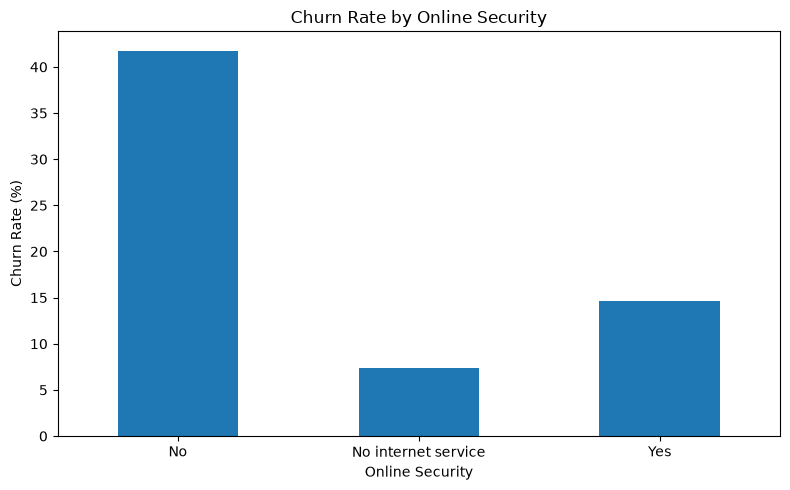

In [56]:
online_security_churn_rate.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Online Security")
plt.xlabel("Online Security")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [57]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [58]:
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (7043, 19)
y shape: (7043,)


In [59]:
X.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65


In [60]:
y.head()

0     No
1     No
2    Yes
3     No
4    Yes
Name: Churn, dtype: str

In [61]:
y = y.map({
    "No": 0,
    "Yes": 1
})

y.head()

0    0
1    0
2    1
3    0
4    1
Name: Churn, dtype: int64

In [62]:
print(y.value_counts())
print("Missing values:", y.isna().sum())

Churn
0    5174
1    1869
Name: count, dtype: int64
Missing values: 0


In [63]:
categorical_cols = X.select_dtypes(include=["object", "string"]).columns

categorical_cols

Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='str')

In [64]:
numerical_cols = X.select_dtypes(include=["number"]).columns

numerical_cols

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='str')

In [65]:
print("Categorical columns:", len(categorical_cols))
print("Numerical columns:", len(numerical_cols))
print("Total:", len(categorical_cols) + len(numerical_cols))

Categorical columns: 15
Numerical columns: 4
Total: 19


In [66]:
pd.get_dummies(
    X["InternetService"],
    prefix="InternetService",
    dtype=int
).head()

,InternetService_DSL,InternetService_Fiber optic,InternetService_No
0,1,0,0
1,1,0,0
2,1,0,0
3,1,0,0
4,0,1,0


In [67]:
import sklearn

print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.9.1


In [68]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5634, 19)
X_test: (1409, 19)
y_train: (5634,)
y_test: (1409,)


In [69]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training target distribution:
Churn
0    73.464679
1    26.535321
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    73.456352
1    26.543648
Name: proportion, dtype: float64


In [70]:
y_train.value_counts()

Churn
0    4139
1    1495
Name: count, dtype: int64

In [71]:
y_train.value_counts(normalize=True) * 100

Churn
0    73.464679
1    26.535321
Name: proportion, dtype: float64

In [72]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore"
            ),
            categorical_cols
        ),
        (
            "num",
            "passthrough",
            numerical_cols
        )
    ]
)

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [73]:
X_train_processed = preprocessor.fit_transform(X_train)

print("Original X_train shape:", X_train.shape)
print("Processed X_train shape:", X_train_processed.shape)

Original X_train shape: (5634, 19)
Processed X_train shape: (5634, 30)


In [74]:
feature_names = preprocessor.get_feature_names_out()

print("Number of processed features:", len(feature_names))

for feature in feature_names:
    print(feature)

Number of processed features: 30
cat__gender_Male
cat__Partner_Yes
cat__Dependents_Yes
cat__PhoneService_Yes
cat__MultipleLines_No phone service
cat__MultipleLines_Yes
cat__InternetService_Fiber optic
cat__InternetService_No
cat__OnlineSecurity_No internet service
cat__OnlineSecurity_Yes
cat__OnlineBackup_No internet service
cat__OnlineBackup_Yes
cat__DeviceProtection_No internet service
cat__DeviceProtection_Yes
cat__TechSupport_No internet service
cat__TechSupport_Yes
cat__StreamingTV_No internet service
cat__StreamingTV_Yes
cat__StreamingMovies_No internet service
cat__StreamingMovies_Yes
cat__Contract_One year
cat__Contract_Two year
cat__PaperlessBilling_Yes
cat__PaymentMethod_Credit card (automatic)
cat__PaymentMethod_Electronic check
cat__PaymentMethod_Mailed check
num__SeniorCitizen
num__tenure
num__MonthlyCharges
num__TotalCharges


In [75]:
X_test_processed = preprocessor.transform(X_test)

print("Original X_test shape:", X_test.shape)
print("Processed X_test shape:", X_test_processed.shape)

Original X_test shape: (1409, 19)
Processed X_test shape: (1409, 30)


In [76]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train_processed, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


d:\Customer Churn Analysis & Prediction\churn_env\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [77]:
log_model = LogisticRegression(max_iter=1000)

In [78]:
log_model.fit(X_train_processed, y_train)

d:\Customer Churn Analysis & Prediction\churn_env\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [79]:
from sklearn.preprocessing import StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore"
            ),
            categorical_cols
        ),
        (
            "num",
            StandardScaler(),
            numerical_cols
        )
    ]
)

In [80]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("X_train processed:", X_train_processed.shape)
print("X_test processed:", X_test_processed.shape)

print("\nFirst 5 processed rows:")
print(X_train_processed[:5])

X_train processed: (5634, 30)
X_test processed: (1409, 30)

First 5 processed rows:
[[ 1.          0.          0.          0.          1.          0.
   0.          0.          0.          0.          0.          0.
   0.          1.          0.          0.          0.          1.
   0.          1.          0.          0.          0.          0.
   1.          0.         -0.44177295  0.10237124 -0.52197565 -0.2622572 ]
 [ 1.          1.          1.          1.          0.          0.
   1.          0.          0.          1.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          1.         -0.44177295 -0.71174346  0.33747781 -0.50363479]
 [ 1.          1.          1.          0.          1.          0.
   0.          0.          0.          1.          0.          1.
   0.          0.          0.          1.          0.          0.
   0.          0.          0.          1

In [81]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train_processed, y_train)

print("Model trained successfully!")
print("Iterations used:", log_model.n_iter_)

Model trained successfully!
Iterations used: [49]


In [82]:
y_pred = log_model.predict(X_test_processed)

print("Number of predictions:", len(y_pred))
print("First 20 predictions:")
print(y_pred[:20])

Number of predictions: 1409
First 20 predictions:
[0 1 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 0 0]


In [83]:
import pandas as pd

comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print(comparison.head(20))

    Actual  Predicted
0        0          0
1        0          1
2        0          0
3        0          0
4        0          0
5        0          1
6        0          0
7        0          0
8        0          0
9        1          0
10       0          0
11       0          0
12       0          0
13       1          1
14       0          0
15       0          0
16       0          0
17       0          1
18       0          0
19       0          0


In [84]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[927 108]
 [164 210]]


In [85]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

Accuracy:  0.8070
Precision: 0.6604
Recall:    0.5615
F1 Score:  0.6069


In [86]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"]
))

              precision    recall  f1-score   support

    No Churn       0.85      0.90      0.87      1035
       Churn       0.66      0.56      0.61       374

    accuracy                           0.81      1409
   macro avg       0.76      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [87]:
from sklearn.metrics import roc_auc_score

y_prob = log_model.predict_proba(X_test_processed)[:, 1]

roc_auc = roc_auc_score(y_test, y_prob)

print("First 10 churn probabilities:")
print(y_prob[:10])

print(f"\nROC-AUC Score: {roc_auc:.4f}")


First 10 churn probabilities:
[0.0458386  0.68375823 0.06007238 0.39936455 0.02161438 0.60226845
 0.44714269 0.12890608 0.00289668 0.39605096]

ROC-AUC Score: 0.8422


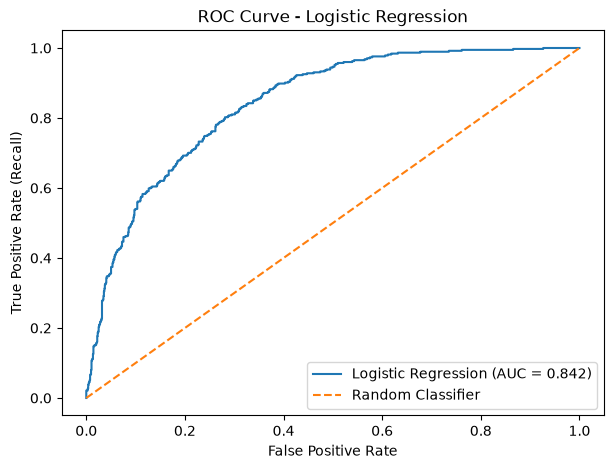

In [88]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve - Logistic Regression")
plt.legend()

plt.show()

In [89]:
from sklearn.metrics import precision_score, recall_score, f1_score

for threshold in [0.30, 0.40, 0.50, 0.60, 0.70]:
    
    y_pred_threshold = (y_prob >= threshold).astype(int)
    
    precision = precision_score(y_test, y_pred_threshold)
    recall = recall_score(y_test, y_pred_threshold)
    f1 = f1_score(y_test, y_pred_threshold)
    
    print(f"Threshold: {threshold:.2f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1 Score:  {f1:.4f}")
    print("-" * 30)

Threshold: 0.30
Precision: 0.5193
Recall:    0.7540
F1 Score:  0.6150
------------------------------
Threshold: 0.40
Precision: 0.5708
Recall:    0.6684
F1 Score:  0.6158
------------------------------
Threshold: 0.50
Precision: 0.6604
Recall:    0.5615
F1 Score:  0.6069
------------------------------
Threshold: 0.60
Precision: 0.7177
Recall:    0.4011
F1 Score:  0.5146
------------------------------
Threshold: 0.70
Precision: 0.7419
Recall:    0.1845
F1 Score:  0.2955
------------------------------


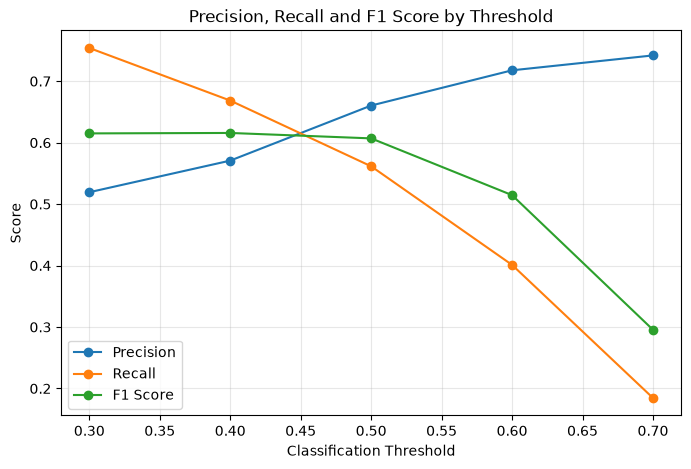

In [90]:
thresholds_test = [0.30, 0.40, 0.50, 0.60, 0.70]

precision_scores = []
recall_scores = []
f1_scores = []

for threshold in thresholds_test:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    precision_scores.append(
        precision_score(y_test, y_pred_threshold)
    )
    
    recall_scores.append(
        recall_score(y_test, y_pred_threshold)
    )
    
    f1_scores.append(
        f1_score(y_test, y_pred_threshold)
    )

plt.figure(figsize=(8, 5))

plt.plot(thresholds_test, precision_scores, marker="o", label="Precision")
plt.plot(thresholds_test, recall_scores, marker="o", label="Recall")
plt.plot(thresholds_test, f1_scores, marker="o", label="F1 Score")

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1 Score by Threshold")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [91]:
feature_names = preprocessor.get_feature_names_out()

coefficients = log_model.coef_[0]

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coef_df = coef_df.sort_values(
    by="Coefficient",
    ascending=False
)

print(coef_df)

                                       Feature  Coefficient
6             cat__InternetService_Fiber optic     1.182298
29                           num__TotalCharges     0.523110
24         cat__PaymentMethod_Electronic check     0.383863
17                        cat__StreamingTV_Yes     0.377500
19                    cat__StreamingMovies_Yes     0.376065
22                   cat__PaperlessBilling_Yes     0.371284
5                       cat__MultipleLines_Yes     0.362275
25             cat__PaymentMethod_Mailed check     0.075442
26                          num__SeniorCitizen     0.054651
13                   cat__DeviceProtection_Yes     0.035237
0                             cat__gender_Male     0.022561
1                             cat__Partner_Yes     0.021550
23  cat__PaymentMethod_Credit card (automatic)    -0.030080
11                       cat__OnlineBackup_Yes    -0.097690
14        cat__TechSupport_No internet service    -0.173381
16        cat__StreamingTV_No internet s

In [92]:
import numpy as np

coef_df["Odds_Ratio"] = np.exp(coef_df["Coefficient"])

print(
    coef_df[
        ["Feature", "Coefficient", "Odds_Ratio"]
    ].to_string(index=False)
)

                                   Feature  Coefficient  Odds_Ratio
          cat__InternetService_Fiber optic     1.182298    3.261862
                         num__TotalCharges     0.523110    1.687267
       cat__PaymentMethod_Electronic check     0.383863    1.467944
                      cat__StreamingTV_Yes     0.377500    1.458634
                  cat__StreamingMovies_Yes     0.376065    1.456541
                 cat__PaperlessBilling_Yes     0.371284    1.449594
                    cat__MultipleLines_Yes     0.362275    1.436593
           cat__PaymentMethod_Mailed check     0.075442    1.078360
                        num__SeniorCitizen     0.054651    1.056172
                 cat__DeviceProtection_Yes     0.035237    1.035865
                          cat__gender_Male     0.022561    1.022818
                          cat__Partner_Yes     0.021550    1.021784
cat__PaymentMethod_Credit card (automatic)    -0.030080    0.970368
                     cat__OnlineBackup_Yes    -0

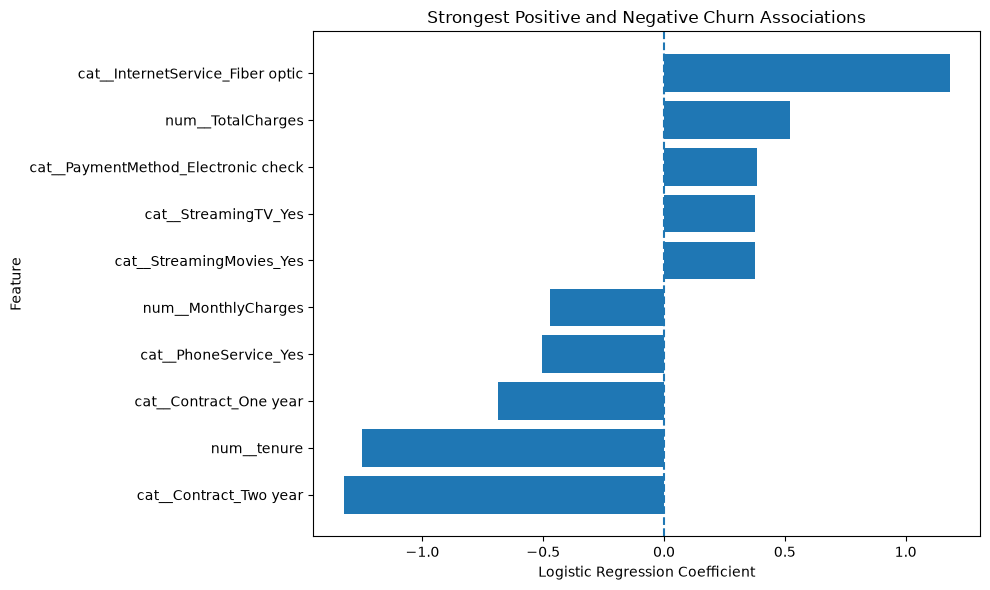

In [93]:
top_positive = coef_df.nlargest(5, "Coefficient")
top_negative = coef_df.nsmallest(5, "Coefficient")

top_features = pd.concat([
    top_negative,
    top_positive
]).sort_values("Coefficient")

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.title("Strongest Positive and Negative Churn Associations")

plt.tight_layout()
plt.show()

In [94]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

print(rf_model)

RandomForestClassifier(class_weight='balanced', n_estimators=200,
                       random_state=42)


In [95]:
rf_model.fit(
    X_train_processed,
    y_train
)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [96]:
rf_pred = rf_model.predict(X_test_processed)

print("Number of predictions:", len(rf_pred))
print("First 20 predictions:")
print(rf_pred[:20])

Number of predictions: 1409
First 20 predictions:
[0 1 0 0 0 1 1 0 0 1 0 0 0 1 0 0 0 1 0 0]


In [97]:
from sklearn.metrics import confusion_matrix

rf_cm = confusion_matrix(
    y_test,
    rf_pred
)

print("Random Forest Confusion Matrix:")
print(rf_cm)

Random Forest Confusion Matrix:
[[846 189]
 [130 244]]


In [98]:
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)

print(f"Random Forest Accuracy:  {rf_accuracy:.4f}")
print(f"Random Forest Precision: {rf_precision:.4f}")
print(f"Random Forest Recall:    {rf_recall:.4f}")
print(f"Random Forest F1 Score:  {rf_f1:.4f}")

Random Forest Accuracy:  0.7736
Random Forest Precision: 0.5635
Random Forest Recall:    0.6524
Random Forest F1 Score:  0.6047


In [99]:
rf_prob = rf_model.predict_proba(
    X_test_processed
)[:, 1]

rf_roc_auc = roc_auc_score(
    y_test,
    rf_prob
)

print("First 10 Random Forest churn probabilities:")
print(rf_prob[:10])

print(f"\nRandom Forest ROC-AUC: {rf_roc_auc:.4f}")

First 10 Random Forest churn probabilities:
[0.    0.875 0.135 0.415 0.01  0.565 0.54  0.19  0.035 0.615]

Random Forest ROC-AUC: 0.8240


In [100]:
log_accuracy = accuracy_score(y_test, y_pred)
log_precision = precision_score(y_test, y_pred)
log_recall = recall_score(y_test, y_pred)
log_f1 = f1_score(y_test, y_pred)

In [101]:
model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [log_accuracy, rf_accuracy],
    "Precision": [log_precision, rf_precision],
    "Recall": [log_recall, rf_recall],
    "F1 Score": [log_f1, rf_f1],
    "ROC-AUC": [roc_auc, rf_roc_auc]
})

print(model_comparison.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
0  Logistic Regression    0.8070     0.6604  0.5615    0.6069   0.8422
1        Random Forest    0.7736     0.5635  0.6524    0.6047   0.8240


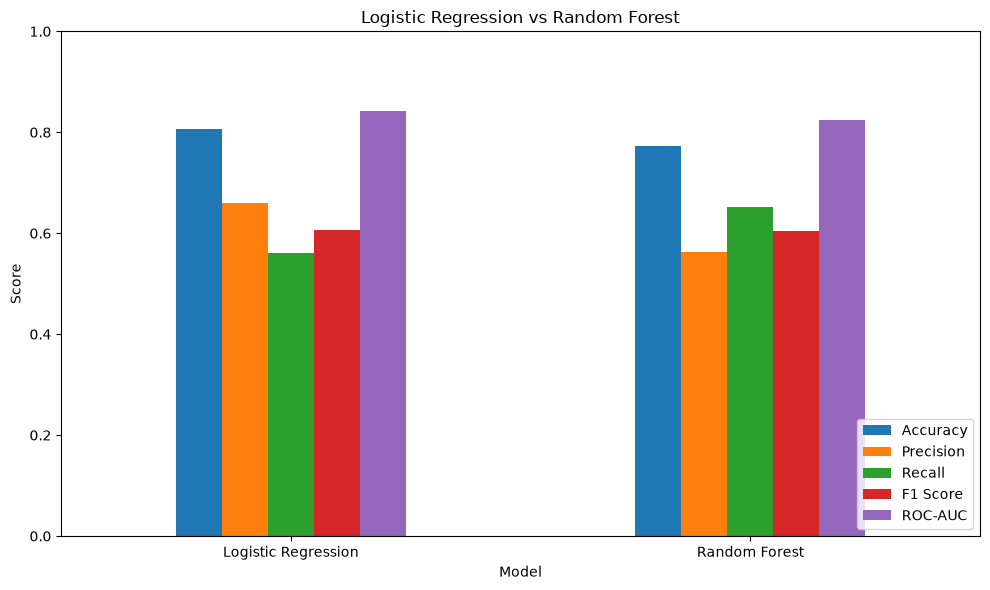

In [102]:
comparison_plot = model_comparison.set_index("Model")

comparison_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Logistic Regression vs Random Forest")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [103]:
rf_feature_importance = pd.DataFrame({
    "Feature": preprocessor.get_feature_names_out(),
    "Importance": rf_model.feature_importances_
})

rf_feature_importance = rf_feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(rf_feature_importance)

                                       Feature  Importance
29                           num__TotalCharges    0.178480
27                                 num__tenure    0.163980
28                         num__MonthlyCharges    0.150326
21                      cat__Contract_Two year    0.063331
6             cat__InternetService_Fiber optic    0.043051
24         cat__PaymentMethod_Electronic check    0.035555
20                      cat__Contract_One year    0.029280
0                             cat__gender_Male    0.025884
9                      cat__OnlineSecurity_Yes    0.025514
22                   cat__PaperlessBilling_Yes    0.024727
15                        cat__TechSupport_Yes    0.023630
1                             cat__Partner_Yes    0.021983
11                       cat__OnlineBackup_Yes    0.021113
2                          cat__Dependents_Yes    0.019242
13                   cat__DeviceProtection_Yes    0.017860
5                       cat__MultipleLines_Yes    0.0175

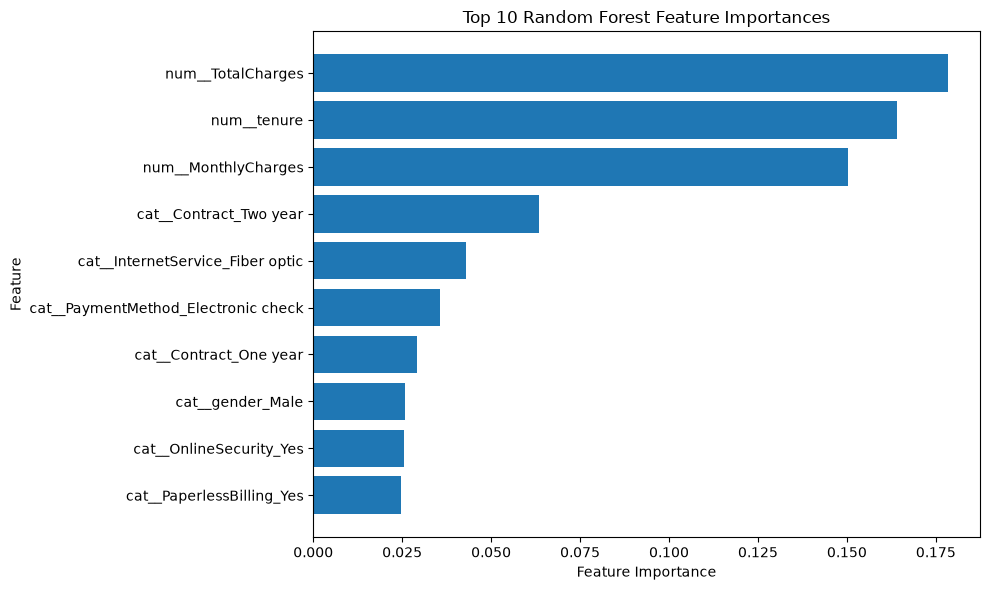

In [104]:
top_10_rf = rf_feature_importance.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_rf["Feature"],
    top_10_rf["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 10 Random Forest Feature Importances")

plt.tight_layout()
plt.show()

In [105]:
rf_train_accuracy = rf_model.score(
    X_train_processed,
    y_train
)

rf_test_accuracy = rf_model.score(
    X_test_processed,
    y_test
)

print(f"Random Forest Training Accuracy: {rf_train_accuracy:.4f}")
print(f"Random Forest Testing Accuracy:  {rf_test_accuracy:.4f}")
print(f"Accuracy Gap: {rf_train_accuracy - rf_test_accuracy:.4f}")

Random Forest Training Accuracy: 0.9947
Random Forest Testing Accuracy:  0.7736
Accuracy Gap: 0.2211


In [106]:
RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.

In [107]:
rf_tuned = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42
)

rf_tuned.fit(
    X_train_processed,
    y_train
)

print("Tuned Random Forest trained successfully!")

Tuned Random Forest trained successfully!


In [108]:
rf_tuned_train_accuracy = rf_tuned.score(
    X_train_processed,
    y_train
)

rf_tuned_test_accuracy = rf_tuned.score(
    X_test_processed,
    y_test
)

rf_tuned_gap = (
    rf_tuned_train_accuracy - rf_tuned_test_accuracy
)

print(
    f"Tuned RF Training Accuracy: "
    f"{rf_tuned_train_accuracy:.4f}"
)

print(
    f"Tuned RF Testing Accuracy:  "
    f"{rf_tuned_test_accuracy:.4f}"
)

print(
    f"Accuracy Gap: "
    f"{rf_tuned_gap:.4f}"
)

Tuned RF Training Accuracy: 0.7856
Tuned RF Testing Accuracy:  0.7516
Accuracy Gap: 0.0340


In [109]:
# Predictions
rf_tuned_pred = rf_tuned.predict(
    X_test_processed
)

# Churn probabilities
rf_tuned_prob = rf_tuned.predict_proba(
    X_test_processed
)[:, 1]

# Metrics
rf_tuned_accuracy = accuracy_score(
    y_test, rf_tuned_pred
)

rf_tuned_precision = precision_score(
    y_test, rf_tuned_pred
)

rf_tuned_recall = recall_score(
    y_test, rf_tuned_pred
)

rf_tuned_f1 = f1_score(
    y_test, rf_tuned_pred
)

rf_tuned_auc = roc_auc_score(
    y_test, rf_tuned_prob
)

print(f"Accuracy:  {rf_tuned_accuracy:.4f}")
print(f"Precision: {rf_tuned_precision:.4f}")
print(f"Recall:    {rf_tuned_recall:.4f}")
print(f"F1 Score:  {rf_tuned_f1:.4f}")
print(f"ROC-AUC:   {rf_tuned_auc:.4f}")

Accuracy:  0.7516
Precision: 0.5209
Recall:    0.7995
F1 Score:  0.6308
ROC-AUC:   0.8439


In [110]:
rf_tuned_cm = confusion_matrix(
    y_test,
    rf_tuned_pred
)

print("Tuned Random Forest Confusion Matrix:")
print(rf_tuned_cm)

Tuned Random Forest Confusion Matrix:
[[760 275]
 [ 75 299]]


In [111]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Original Random Forest",
        "Tuned Random Forest"
    ],

    "Accuracy": [
        log_accuracy,
        rf_accuracy,
        rf_tuned_accuracy
    ],

    "Precision": [
        log_precision,
        rf_precision,
        rf_tuned_precision
    ],

    "Recall": [
        log_recall,
        rf_recall,
        rf_tuned_recall
    ],

    "F1 Score": [
        log_f1,
        rf_f1,
        rf_tuned_f1
    ],

    "ROC-AUC": [
        roc_auc,
        rf_roc_auc,
        rf_tuned_auc
    ]
})

print(model_comparison.round(4))

                    Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
0     Logistic Regression    0.8070     0.6604  0.5615    0.6069   0.8422
1  Original Random Forest    0.7736     0.5635  0.6524    0.6047   0.8240
2     Tuned Random Forest    0.7516     0.5209  0.7995    0.6308   0.8439


In [112]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [5, 8, 12],
    "min_samples_split": [5, 10],
    "min_samples_leaf": [2, 5]
}

rf_for_tuning = RandomForestClassifier(
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

grid_search = GridSearchCV(
    estimator=rf_for_tuning,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(
    X_train_processed,
    y_train
)

print("Grid search completed!")

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Grid search completed!


In [113]:
print("Best Parameters:")
print(grid_search.best_params_)

print(
    f"\nBest Cross-Validation ROC-AUC: "
    f"{grid_search.best_score_:.4f}"
)

Best Parameters:
{'max_depth': 8, 'min_samples_leaf': 5, 'min_samples_split': 5, 'n_estimators': 200}

Best Cross-Validation ROC-AUC: 0.8465


In [114]:
best_rf = grid_search.best_estimator_

print(best_rf)

RandomForestClassifier(class_weight='balanced', max_depth=8, min_samples_leaf=5,
                       min_samples_split=5, n_estimators=200, n_jobs=-1,
                       random_state=42)


In [115]:
# Make predictions
best_rf_pred = best_rf.predict(
    X_test_processed
)

# Predict churn probabilities
best_rf_prob = best_rf.predict_proba(
    X_test_processed
)[:, 1]

# Calculate metrics
best_rf_accuracy = accuracy_score(
    y_test, best_rf_pred
)

best_rf_precision = precision_score(
    y_test, best_rf_pred
)

best_rf_recall = recall_score(
    y_test, best_rf_pred
)

best_rf_f1 = f1_score(
    y_test, best_rf_pred
)

best_rf_auc = roc_auc_score(
    y_test, best_rf_prob
)

print(f"Accuracy:  {best_rf_accuracy:.4f}")
print(f"Precision: {best_rf_precision:.4f}")
print(f"Recall:    {best_rf_recall:.4f}")
print(f"F1 Score:  {best_rf_f1:.4f}")
print(f"ROC-AUC:   {best_rf_auc:.4f}")

Accuracy:  0.7516
Precision: 0.5209
Recall:    0.7995
F1 Score:  0.6308
ROC-AUC:   0.8439


In [116]:
best_rf_train_accuracy = best_rf.score(
    X_train_processed,
    y_train
)

best_rf_test_accuracy = best_rf.score(
    X_test_processed,
    y_test
)

best_rf_gap = (
    best_rf_train_accuracy - best_rf_test_accuracy
)

print(
    f"Best RF Training Accuracy: "
    f"{best_rf_train_accuracy:.4f}"
)

print(
    f"Best RF Testing Accuracy:  "
    f"{best_rf_test_accuracy:.4f}"
)

print(
    f"Accuracy Gap: "
    f"{best_rf_gap:.4f}"
)

Best RF Training Accuracy: 0.7856
Best RF Testing Accuracy:  0.7516
Accuracy Gap: 0.0340


In [117]:
final_model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Original Random Forest",
        "CV-Selected Random Forest"
    ],

    "Accuracy": [
        log_accuracy,
        rf_accuracy,
        best_rf_accuracy
    ],

    "Precision": [
        log_precision,
        rf_precision,
        best_rf_precision
    ],

    "Recall": [
        log_recall,
        rf_recall,
        best_rf_recall
    ],

    "F1 Score": [
        log_f1,
        rf_f1,
        best_rf_f1
    ],

    "ROC-AUC": [
        roc_auc,
        rf_roc_auc,
        best_rf_auc
    ]
})

print(final_model_comparison.round(4))

                       Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
0        Logistic Regression    0.8070     0.6604  0.5615    0.6069   0.8422
1     Original Random Forest    0.7736     0.5635  0.6524    0.6047   0.8240
2  CV-Selected Random Forest    0.7516     0.5209  0.7995    0.6308   0.8439


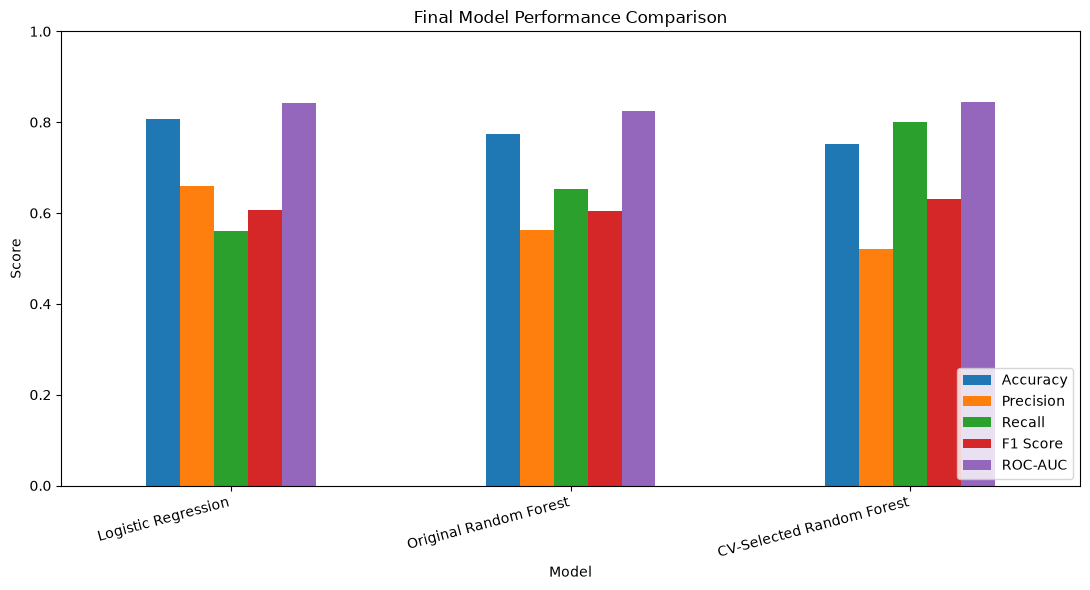

In [118]:
comparison_plot = final_model_comparison.set_index("Model")

comparison_plot.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Final Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)

plt.xticks(
    rotation=15,
    ha="right"
)

plt.legend(
    loc="lower right"
)

plt.tight_layout()
plt.show()

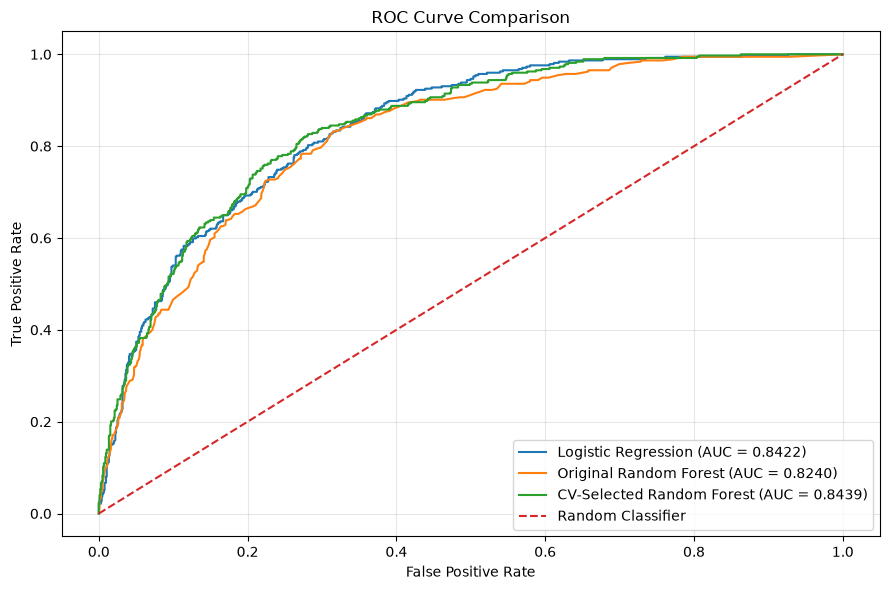

In [119]:
from sklearn.metrics import roc_curve

# Logistic Regression
log_fpr, log_tpr, _ = roc_curve(
    y_test,
    y_prob
)

# Original Random Forest
rf_fpr, rf_tpr, _ = roc_curve(
    y_test,
    rf_prob
)

# CV-Selected Random Forest
best_rf_fpr, best_rf_tpr, _ = roc_curve(
    y_test,
    best_rf_prob
)

plt.figure(figsize=(9, 6))

plt.plot(
    log_fpr,
    log_tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.4f})"
)

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f"Original Random Forest (AUC = {rf_roc_auc:.4f})"
)

plt.plot(
    best_rf_fpr,
    best_rf_tpr,
    label=f"CV-Selected Random Forest (AUC = {best_rf_auc:.4f})"
)

# Random-classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Final Model Evaluation Summary

Three classification models/configurations were evaluated:

### 1. Logistic Regression
- Accuracy: 0.8070
- Precision: 0.6604
- Recall: 0.5615
- F1 Score: 0.6069
- ROC-AUC: 0.8422

Logistic Regression achieved the highest accuracy and precision among the
evaluated models. However, its lower recall indicates that it missed a
larger proportion of customers who actually churned.

### 2. Original Random Forest
- Accuracy: 0.7736
- Precision: 0.5635
- Recall: 0.6524
- F1 Score: 0.6047
- ROC-AUC: 0.8240

The original Random Forest showed substantial overfitting, with training
accuracy of 0.9947 compared with test accuracy of 0.7736.

### 3. Cross-Validation-Selected Random Forest
- Accuracy: 0.7516
- Precision: 0.5209
- Recall: 0.7995
- F1 Score: 0.6308
- ROC-AUC: 0.8439

Random Forest hyperparameters were selected using 5-fold cross-validation.
The selected configuration was:

- max_depth = 8
- min_samples_leaf = 5
- min_samples_split = 5
- n_estimators = 200
- class_weight = "balanced"

The selected model substantially reduced the training-test accuracy gap
from 0.2211 to 0.0340.

### Business Interpretation

The models demonstrate a precision-recall trade-off.

Logistic Regression produces fewer false-positive churn alerts and has
higher overall accuracy and precision.

The cross-validation-selected Random Forest identifies a much larger
proportion of actual churners, achieving approximately 80% recall, but
also produces more false-positive churn predictions.

Therefore, model selection should depend on the business cost of missing
a customer who is likely to churn compared with the cost of unnecessary
retention interventions.

The Logistic Regression and cross-validation-selected Random Forest have
very similar ROC-AUC scores, indicating similar overall ability to rank
customers by churn risk across classification thresholds.

In [120]:
from sklearn.pipeline import Pipeline
from sklearn.base import clone

final_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", RandomForestClassifier(
            class_weight="balanced",
            max_depth=8,
            min_samples_leaf=5,
            min_samples_split=5,
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

final_pipeline.fit(
    X_train,
    y_train
)

print("Final pipeline trained successfully!")

Final pipeline trained successfully!


In [121]:
# Predictions directly from the original test data
pipeline_pred = final_pipeline.predict(X_test)

# Churn probabilities
pipeline_prob = final_pipeline.predict_proba(X_test)[:, 1]

# Evaluation metrics
pipeline_accuracy = accuracy_score(
    y_test, pipeline_pred
)

pipeline_precision = precision_score(
    y_test, pipeline_pred
)

pipeline_recall = recall_score(
    y_test, pipeline_pred
)

pipeline_f1 = f1_score(
    y_test, pipeline_pred
)

pipeline_auc = roc_auc_score(
    y_test, pipeline_prob
)

print(f"Pipeline Accuracy:  {pipeline_accuracy:.4f}")
print(f"Pipeline Precision: {pipeline_precision:.4f}")
print(f"Pipeline Recall:    {pipeline_recall:.4f}")
print(f"Pipeline F1 Score:  {pipeline_f1:.4f}")
print(f"Pipeline ROC-AUC:   {pipeline_auc:.4f}")

Pipeline Accuracy:  0.7516
Pipeline Precision: 0.5209
Pipeline Recall:    0.7995
Pipeline F1 Score:  0.6308
Pipeline ROC-AUC:   0.8439


In [122]:
import joblib
from pathlib import Path

# Create models folder if it does not already exist
models_dir = Path("../models")
models_dir.mkdir(exist_ok=True)

# Save complete preprocessing + model pipeline
model_path = models_dir / "churn_prediction_pipeline.joblib"

joblib.dump(
    final_pipeline,
    model_path
)

print(f"Pipeline saved to: {model_path}")

Pipeline saved to: ..\models\churn_prediction_pipeline.joblib


In [123]:
# Load the saved pipeline
loaded_pipeline = joblib.load(
    "../models/churn_prediction_pipeline.joblib"
)

print("Pipeline loaded successfully!")

Pipeline loaded successfully!


In [124]:
# Make predictions using the loaded pipeline
loaded_pred = loaded_pipeline.predict(X_test)

loaded_prob = loaded_pipeline.predict_proba(
    X_test
)[:, 1]

print("Number of predictions:", len(loaded_pred))

print(
    "First 10 predictions:",
    loaded_pred[:10]
)

print(
    "First 10 churn probabilities:",
    loaded_prob[:10]
)

Number of predictions: 1409
First 10 predictions: [0 1 0 1 0 1 1 0 0 1]
First 10 churn probabilities: [0.06424099 0.84662222 0.22706813 0.59114625 0.05472627 0.72051942
 0.62526148 0.15976556 0.02456976 0.61018548]


In [125]:
import numpy as np

same_predictions = np.array_equal(
    pipeline_pred,
    loaded_pred
)

same_probabilities = np.allclose(
    pipeline_prob,
    loaded_prob
)

print(
    "Predictions identical:",
    same_predictions
)

print(
    "Probabilities identical:",
    same_probabilities
)

Predictions identical: True
Probabilities identical: True


In [126]:
# Create a results DataFrame for the test customers
test_results = df.loc[X_test.index, ["customerID"]].copy()

# Actual churn
test_results["Actual_Churn"] = y_test.map({
    0: "No",
    1: "Yes"
})

# Predicted churn
test_results["Predicted_Churn"] = pipeline_pred

test_results["Predicted_Churn"] = test_results[
    "Predicted_Churn"
].map({
    0: "No",
    1: "Yes"
})

# Predicted probability of churn
test_results["Churn_Probability"] = pipeline_prob

print(test_results.head(10))
print("\nShape:", test_results.shape)

      customerID Actual_Churn Predicted_Churn  Churn_Probability
437   4376-KFVRS           No              No           0.064241
2280  2754-SDJRD           No             Yes           0.846622
2235  9917-KWRBE           No              No           0.227068
4460  0365-GXEZS           No             Yes           0.591146
3761  9385-NXKDA           No              No           0.054726
5748  4686-UXDML           No             Yes           0.720519
3568  2227-JRSJX           No             Yes           0.625261
2976  4830-FAXFM           No              No           0.159766
5928  1830-IPXVJ           No              No           0.024570
1639  4690-LLKUA          Yes             Yes           0.610185

Shape: (1409, 4)


In [127]:
def assign_risk(probability):
    if probability < 0.30:
        return "Low Risk"
    elif probability < 0.60:
        return "Medium Risk"
    else:
        return "High Risk"


test_results["Risk_Level"] = test_results[
    "Churn_Probability"
].apply(assign_risk)

print(test_results.head(10))

      customerID Actual_Churn Predicted_Churn  Churn_Probability   Risk_Level
437   4376-KFVRS           No              No           0.064241     Low Risk
2280  2754-SDJRD           No             Yes           0.846622    High Risk
2235  9917-KWRBE           No              No           0.227068     Low Risk
4460  0365-GXEZS           No             Yes           0.591146  Medium Risk
3761  9385-NXKDA           No              No           0.054726     Low Risk
5748  4686-UXDML           No             Yes           0.720519    High Risk
3568  2227-JRSJX           No             Yes           0.625261    High Risk
2976  4830-FAXFM           No              No           0.159766     Low Risk
5928  1830-IPXVJ           No              No           0.024570     Low Risk
1639  4690-LLKUA          Yes             Yes           0.610185    High Risk


In [128]:
print(
    test_results["Risk_Level"].value_counts()
)

Risk_Level
Low Risk       601
High Risk      454
Medium Risk    354
Name: count, dtype: int64


In [129]:
print(
    test_results["Risk_Level"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Risk_Level
Low Risk       42.65
High Risk      32.22
Medium Risk    25.12
Name: proportion, dtype: float64


In [130]:
from pathlib import Path

# Create output folder
output_dir = Path("../outputs")
output_dir.mkdir(exist_ok=True)

# Save prediction results
output_path = output_dir / "churn_prediction_results.csv"

test_results.to_csv(
    output_path,
    index=False
)

print(f"Prediction results saved to: {output_path}")

Prediction results saved to: ..\outputs\churn_prediction_results.csv


In [131]:
check_results = pd.read_csv(
    "../outputs/churn_prediction_results.csv"
)

print(check_results.head())
print("\nShape:", check_results.shape)
print("\nColumns:")
print(check_results.columns.tolist())

   customerID Actual_Churn Predicted_Churn  Churn_Probability   Risk_Level
0  4376-KFVRS           No              No           0.064241     Low Risk
1  2754-SDJRD           No             Yes           0.846622    High Risk
2  9917-KWRBE           No              No           0.227068     Low Risk
3  0365-GXEZS           No             Yes           0.591146  Medium Risk
4  9385-NXKDA           No              No           0.054726     Low Risk

Shape: (1409, 5)

Columns:
['customerID', 'Actual_Churn', 'Predicted_Churn', 'Churn_Probability', 'Risk_Level']


In [132]:
# Export the cleaned full dataset for SQL analysis

sql_data_path = "../data/telco_churn_cleaned.csv"

df.to_csv(
    sql_data_path,
    index=False
)

print(
    f"Cleaned SQL dataset saved to: {sql_data_path}"
)

print("Shape:", df.shape)

Cleaned SQL dataset saved to: ../data/telco_churn_cleaned.csv
Shape: (7043, 21)


## Power BI Dataset Preparation

In [133]:
# Merge cleaned customer data with model prediction results
powerbi_df = df.merge(
    test_results[
        [
            "customerID",
            "Predicted_Churn",
            "Churn_Probability",
            "Risk_Level"
        ]
    ],
    on="customerID",
    how="left"
)

print("Shape:", powerbi_df.shape)
powerbi_df.head()

Shape: (7043, 24)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Predicted_Churn,Churn_Probability,Risk_Level
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,NaN,NaN,NaN
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,One year,No,Mailed check,56.95,1889.50,No,NaN,NaN,NaN
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,NaN,NaN,NaN
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,NaN,NaN,NaN
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,NaN,NaN,NaN


In [134]:
print("Total customers:", len(powerbi_df))

print(
    "Customers with predictions:",
    powerbi_df["Churn_Probability"].notna().sum()
)

print(
    "Customers without predictions:",
    powerbi_df["Churn_Probability"].isna().sum()
)

Total customers: 7043
Customers with predictions: 1409
Customers without predictions: 5634


In [135]:
# Save the final dataset for Power BI
powerbi_df.to_csv(
    "../powerbi/telco_churn_powerbi.csv",
    index=False
)

print("Power BI dataset saved successfully.")
print("Shape:", powerbi_df.shape)

Power BI dataset saved successfully.
Shape: (7043, 24)
